
# Notebook 04 — Geographical Analysis and Cluster Interpretation

**Project:** AI-Readiness Investment Intelligence for Africa

**Purpose:** Examine the geographical distribution of the selected K-Means clusters, interpret their infrastructure characteristics, and assess their implications for preliminary investment screening.

**Primary configuration:** K-Means, k = 3

**Comparison configurations:** k = 2 and k = 6

**Analytical dataset:** 2,172 African urban centres, 19 columns.

**Interpretation:** Cluster memberships represent exploratory infrastructure profiles, not validated AI-readiness rankings or investment recommendations.


### Load and verify our final dataset

In [1]:

from pathlib import Path
import pandas as pd

# Notebook is located inside notebooks/
DATA_PATH = Path("../data/processed/urban_centres_cluster_assignments.csv")

df_geo = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_geo.shape)
print("\nColumns:")
print(df_geo.columns.tolist())

print("\nCluster sizes (k=3):")
print(df_geo["KMeans_k3"].value_counts().sort_index())

display(df_geo.head())


Dataset shape: (2172, 19)

Columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GH_POP_TOT_2025', 'SC_GDP_AVG_2020', 'IN_CIS_ENE_2020', 'IN_CIS_TEL_2020', 'fibre_distance_band_km', 'IN_CIS_TRA_2020', 'IN_ROA_DEN_2024', 'SC_SEC_SYT_2020', 'IN_CIS_EDU_2020', 'IN_CIS_WAT_2020', 'CL_REN_PVO_2020', 'CL_B01_CUR_2010', 'peeringdb_facility_count', 'KMeans_k2', 'KMeans_k3', 'KMeans_k6']

Cluster sizes (k=3):
KMeans_k3
0     522
1    1380
2     270
Name: count, dtype: int64


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count,KMeans_k2,KMeans_k3,KMeans_k6
0,38,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0,0,1,2
1,39,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2,1,2,3
2,40,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0,1,2,3
3,41,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0,1,0,0
4,43,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0,0,1,4


## Check available geographical data


### Spatial Data Availability and Mapping Preparation

This section examines the geographical information available for the 2,172 urban centres and identifies the spatial data required to map their cluster assignments.


In [3]:

# Check for geographical coordinate or geometry columns
spatial_keywords = [
    "lat", "lon", "long", "coord",
    "geometry", "geom", "wkt", "centroid"
]

spatial_columns = [
    col for col in df_geo.columns
    if any(key in col.lower() for key in spatial_keywords)
]

print("Spatial columns in analytical dataset:")
print(spatial_columns if spatial_columns else "None found")

# Inspect available files in the project's data folders
project_data = Path("../data")

for folder in ["raw", "interim", "processed"]:
    folder_path = project_data / folder
    print(f"\n{folder.upper()} files:")

    if folder_path.exists():
        files = sorted(
            p.relative_to(project_data)
            for p in folder_path.rglob("*")
            if p.is_file()
        )

        for file in files[:30]:
            print(" -", file)

        if len(files) > 30:
            print(f" ... and {len(files) - 30} more files")
    else:
        print("Folder not found")


Spatial columns in analytical dataset:
None found

RAW files:
 - raw\GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.gpkg
 - raw\GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.xlsx
 - raw\GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg
 - raw\GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.xlsx
 - raw\itu_fibre_results_batch1.csv
 - raw\itu_fibre_results_batch2.csv
 - raw\peeringdb_africa_facilities.csv

INTERIM files:
 - interim\exported_data_20261114_233013_57662141-8eef-44e8-99f7-21d125abfb90.csv
 - interim\exported_data_20261114_234028_1ef12fa6-80f7-4fbe-ad12-c951af1f5c0f.csv
 - interim\exported_data_20261114_234758_ec67b46b-6789-47bf-95eb-4f095b38cf97.csv
 - interim\exported_data_20261115_000325_53ebd6e8-0bbd-4193-86ca-4ba69d4d6249.csv
 - interim\exported_data_20261115_001208_545cd097-5cab-4c99-8f1f-5d59b07ae12f.csv
 - interim\itu_fibre_1086.csv
 - interim\itu_fibre_1086_lookup.csv
 - interim\itu_fibre_all_2172.csv
 - interim\itu_fibre_batch2_1086.csv
 - interim\itu_fibr


## Inspect GHSL Urban Centre Spatial Data

The project already contains GHSL spatial data in the raw-data directory. This section checks the available GeoPackage layers and verifies whether urban-centre geometries can be linked to the finalized clustering dataset using the original urban-centre identifier.


In [4]:

import geopandas as gpd

# Locate existing GHSL GeoPackage files
gpkg_files = sorted(Path("../data/raw").glob("*.gpkg"))

print("Available GeoPackages:")
for i, path in enumerate(gpkg_files, start=1):
    print(f"{i}. {path.name}")

# Inspect the first available GeoPackage
if gpkg_files:
    gpkg_path = gpkg_files[0]

    print("\nGeoPackage layers:")
    print(gpd.list_layers(gpkg_path))
else:
    print("\nNo GeoPackage found in data/raw/")


Available GeoPackages:
1. GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.gpkg
2. GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg

GeoPackage layers:
                                                 name geometry_type
0   GHSL_UCDB_THEME_GENERAL_CHARACTERISTICS_GLOBE_...  MultiPolygon
1                   GHSL_UCDB_THEME_GHSL_GLOBE_R2024A  MultiPolygon
2                GHSL_UCDB_THEME_CLIMATE_GLOBE_R2024A  MultiPolygon
3              GHSL_UCDB_THEME_EMISSIONS_GLOBE_R2024A  MultiPolygon
4               GHSL_UCDB_THEME_EXPOSURE_GLOBE_R2024A  MultiPolygon
5              GHSL_UCDB_THEME_GEOGRAPHY_GLOBE_R2024A  MultiPolygon
6              GHSL_UCDB_THEME_GREENNESS_GLOBE_R2024A  MultiPolygon
7            GHSL_UCDB_THEME_HAZARD_RISK_GLOBE_R2024A  MultiPolygon
8                 GHSL_UCDB_THEME_HEALTH_GLOBE_R2024A  MultiPolygon
9        GHSL_UCDB_THEME_INFRASTRUCTURES_GLOBE_R2024A  MultiPolygon
10                  GHSL_UCDB_THEME_LULC_GLOBE_R2024A  MultiPolygon
11       GHSL_UCDB_THEME_NA

## Verify GHSL Centroid Layers and Urban-Centre Identifiers

In [5]:

# Inspect centroid layers in both regional GeoPackages

for gpkg_path in gpkg_files:
    print(f"\nGeoPackage: {gpkg_path.name}")

    layers = gpd.list_layers(gpkg_path)
    centroid_layers = layers.loc[
        layers["name"].str.contains("centroid", case=False),
        "name"
    ].tolist()

    print("Centroid layers:", centroid_layers)

    for layer_name in centroid_layers:
        centroids = gpd.read_file(
            gpkg_path,
            layer=layer_name
        )

        print("Number of records:", len(centroids))
        print("CRS:", centroids.crs)
        print("Geometry types:", centroids.geom_type.unique())
        print("Columns:", centroids.columns.tolist())

        display(centroids.head(3))



GeoPackage: GHS_UCDB_REGION_NORTHERN_AFRICA_AND_WESTERN_ASIA_R2024A.gpkg
Centroid layers: ['UC_centroids']
Number of records: 11422
CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]
Geometry types: <StringArray>
['Point']
Length: 1, dtype: str
Columns: ['ID_UC_G0', 'GC_UCC_LON_2025', 'GC_UCC_LAT_2025', 'geometry']


,ID_UC_G0,GC_UCC_LON_2025,GC_UCC_LAT_2025,geometry
0,1,-16907128.97,-1704473.775,POINT (-16907128.97 -1704473.775)
1,2,-16819113.61,-2591416.147,POINT (-16819113.61 -2591416.147)
2,3,-15157727.86,2613593.722,POINT (-15157727.86 2613593.722)



GeoPackage: GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg
Centroid layers: ['UC_centroids']
Number of records: 11422
CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]
Geometry types: <StringArray>
['Point']
Length: 1, dtype: str
Columns: ['ID_UC_G0', 'GC_UCC_LON_2025', 'GC_UCC_LAT_2025', 'geometry']


,ID_UC_G0,GC_UCC_LON_2025,GC_UCC_LAT_2025,geometry
0,1,-16907128.97,-1704473.775,POINT (-16907128.97 -1704473.775)
1,2,-16819113.61,-2591416.147,POINT (-16819113.61 -2591416.147)
2,3,-15157727.86,2613593.722,POINT (-15157727.86 2613593.722)



##  Link Cluster Assignments to GHSL Urban-Centre Centroids

The GHSL centroid layer provides spatial point geometries and the urban-centre identifier `ID_UC_G0`. Cluster assignments are linked to these geometries through the common identifier.

The resulting spatial dataset is checked for duplicate identifiers, missing geometries and unmatched urban centres before mapping.


In [6]:

# Load centroid geometries from one GeoPackage
centroids_all = gpd.read_file(
    gpkg_files[0],
    layer="UC_centroids"
)

# Check identifier uniqueness
print("Centroid records:", len(centroids_all))
print(
    "Unique centroid IDs:",
    centroids_all["ID_UC_G0"].nunique()
)
print(
    "Duplicate centroid IDs:",
    centroids_all["ID_UC_G0"].duplicated().sum()
)

print(
    "Duplicate analytical IDs:",
    df_geo["ID_UC_G0"].duplicated().sum()
)

# Keep only identifiers and geometry
centroids_selected = centroids_all[
    ["ID_UC_G0", "geometry"]
].copy()

# Match finalized cluster assignments to centroids
gdf_clusters = df_geo.merge(
    centroids_selected,
    on="ID_UC_G0",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Convert to GeoDataFrame
gdf_clusters = gpd.GeoDataFrame(
    gdf_clusters,
    geometry="geometry",
    crs=centroids_all.crs
)

print("\nJoin results:")
print(gdf_clusters["_merge"].value_counts())

print("\nFinal spatial dataset shape:", gdf_clusters.shape)
print("Missing geometries:", gdf_clusters.geometry.isna().sum())
print("CRS:", gdf_clusters.crs)

display(
    gdf_clusters[
        ["ID_UC_G0", "GC_UCN_MAI_2025",
         "GC_CNT_GAD_2025", "KMeans_k3", "geometry"]
    ].head()
)


Centroid records: 11422
Unique centroid IDs: 11422
Duplicate centroid IDs: 0
Duplicate analytical IDs: 0

Join results:
_merge
both          2172
left_only        0
right_only       0
Name: count, dtype: int64

Final spatial dataset shape: (2172, 21)
Missing geometries: 0
CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,KMeans_k3,geometry
0,38,Mindelo,Cabo Verde,1,POINT (-2436599.789 2076115.058)
1,39,Dakar,Senegal,2,POINT (-1707136.794 1815364.184)
2,40,Serrekunda,Gambia,2,POINT (-1644109.635 1652019.946)
3,41,Nouadhibou,Mauritania,0,POINT (-1636766.99 2568013.525)
4,43,Bissau,Guinea-Bissau,1,POINT (-1544056.039 1463348.022)


### Convert spatial GeoDataFrame to geographic coordinates (WGS 84)

In [7]:
# Convert point geometries to longitude/latitude
gdf_map = gdf_clusters.to_crs(epsg=4326)

print("Mapping CRS:", gdf_map.crs)
print("Urban centres:", len(gdf_map))
print("Cluster counts:")
print(gdf_map["KMeans_k3"].value_counts().sort_index())

Mapping CRS: EPSG:4326
Urban centres: 2172
Cluster counts:
KMeans_k3
0     522
1    1380
2     270
Name: count, dtype: int64


### Cluster Visualization / Infrastructure Profiles across Africa

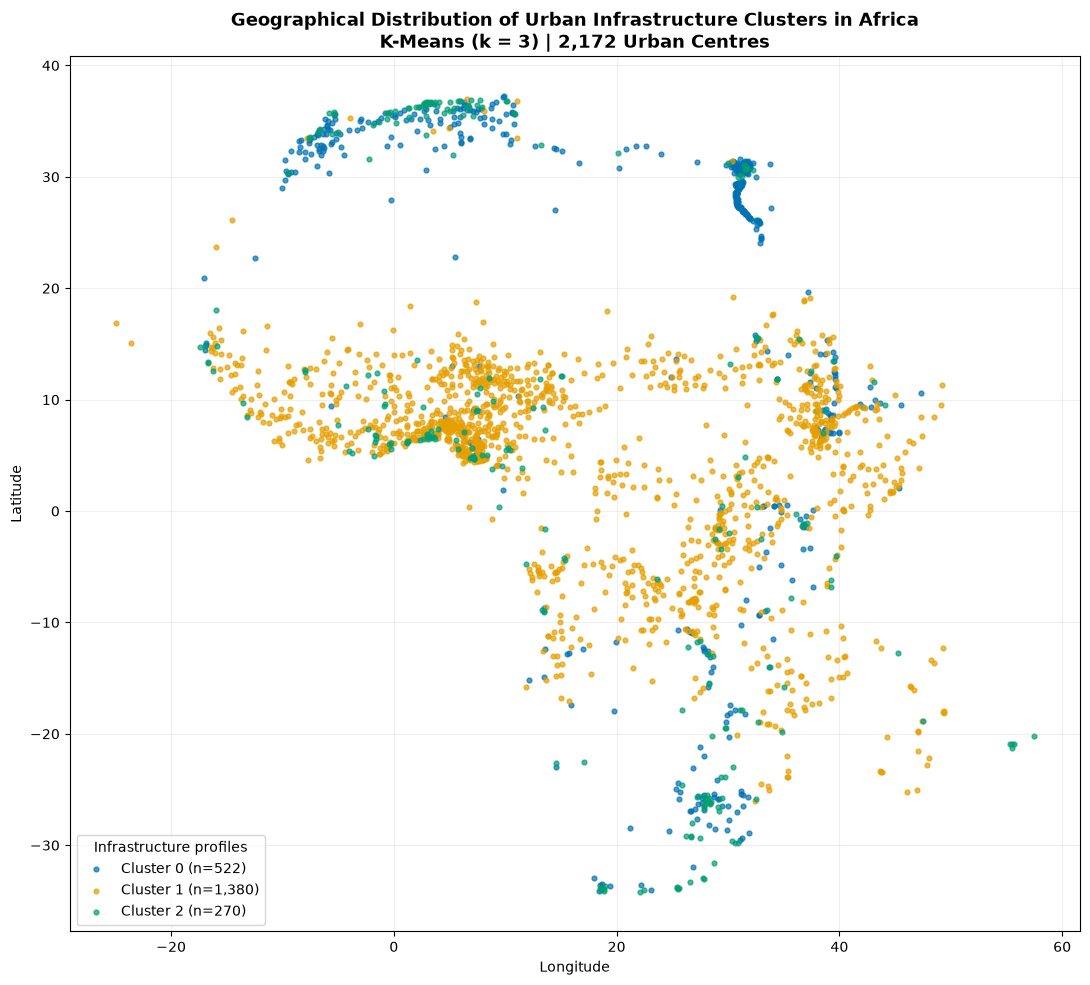

In [8]:
import matplotlib.pyplot as plt

# Three distinct categorical colours (not a ranking)
cluster_colors = {
    0: "#0072B2",  # Blue
    1: "#E69F00",  # Orange
    2: "#009E73"   # Green
}

fig, ax = plt.subplots(figsize=(11, 10))

for cluster_id, color in cluster_colors.items():
    subset = gdf_map[gdf_map["KMeans_k3"] == cluster_id]

    ax.scatter(
        subset.geometry.x,
        subset.geometry.y,
        s=12,
        color=color,
        alpha=0.7,
        label=f"Cluster {cluster_id} (n={len(subset):,})"
    )

ax.set_title(
    "Geographical Distribution of Urban Infrastructure Clusters in Africa\n"
    "K-Means (k = 3) | 2,172 Urban Centres",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Infrastructure profiles", loc="lower left")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Create Africa-wide cluster map

In [9]:
# Inspect the GHSL geography layer
import geopandas as gpd
from pathlib import Path

raw_dir = Path("../data/raw")

gpkg_path = (
    raw_dir /
    "GHS_UCDB_REGION_SUB_SAHARAN_AFRICA_R2024A.gpkg"
)

geography_layer = (
    "GHSL_UCDB_THEME_GEOGRAPHY_GLOBE_R2024A"
)

gdf_geography = gpd.read_file(
    gpkg_path,
    layer=geography_layer,
    rows=5
)

print("Geometry types:")
print(gdf_geography.geom_type.unique())

print("\nAvailable columns:")
print(gdf_geography.columns.tolist())

display(gdf_geography.head(3))

Geometry types:
<StringArray>
['MultiPolygon']
Length: 1, dtype: str

Available columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GE_BIO_A01_2025', 'GE_BIO_A02_2025', 'GE_BIO_A03_2025', 'GE_BIO_A04_2025', 'GE_BIO_A05_2025', 'GE_BIO_A06_2025', 'GE_BIO_A07_2025', 'GE_BIO_A08_2025', 'GE_BIO_A09_2025', 'GE_BIO_A10_2025', 'GE_BIO_A11_2025', 'GE_BIO_A12_2025', 'GE_BIO_A13_2025', 'GE_BIO_A14_2025', 'GE_BIO_A15_2025', 'GE_BIO_A16_2025', 'GE_BIO_A17_2025', 'GE_BIO_A18_2025', 'GE_BIO_A19_2025', 'GE_BIO_A20_2025', 'GE_BIO_A21_2025', 'GE_BIO_A22_2025', 'GE_BIO_A23_2025', 'GE_BIO_A24_2025', 'GE_ECO_CLA_2025', 'GE_ELV_AVG_2025', 'GE_MRB_MAI_2025', 'GE_MRB_LIS_2025', 'GE_SCL_MPC_2023', 'GE_SCL_LST_2023', 'geometry']


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GE_BIO_A01_2025,GE_BIO_A02_2025,GE_BIO_A03_2025,...,GE_BIO_A22_2025,GE_BIO_A23_2025,GE_BIO_A24_2025,GE_ECO_CLA_2025,GE_ELV_AVG_2025,GE_MRB_MAI_2025,GE_MRB_LIS_2025,GE_SCL_MPC_2023,GE_SCL_LST_2023,geometry
0,38,Mindelo,Cabo Verde,18,8.827388e+04,Lower Middle,Sub-Saharan Africa,0.0,0.0,0.0,...,0.0,0.0,0.0,Cape Verde Islands dry forests,38.28,None,None,Regosols,"Arenosols, Cambisols, Leptosols, Regosols","MULTIPOLYGON (((-2436000 2078000, -2435000 207..."
1,39,Dakar,Senegal,277,3.970202e+06,Lower Middle,Sub-Saharan Africa,0.0,0.0,0.0,...,0.0,0.0,0.0,West Sudanian savanna,11.23,None,None,Arenosols,"Arenosols, Cambisols, Fluvisols, Gleysols, Lep...","MULTIPOLYGON (((-1694000 1824000, -1695000 182..."
2,40,Serrekunda,Gambia,181,1.313465e+06,Low income,Sub-Saharan Africa,0.0,0.0,0.0,...,0.0,0.0,0.0,Guinean forest-savanna mosaic,17.81,None,None,Gleysols,"Acrisols, Arenosols, Fluvisols, Gleysols, Lixi...","MULTIPOLYGON (((-1641000 1652000, -1640000 165..."


### Load and inspect the country boundaries

In [10]:

import geopandas as gpd
from pathlib import Path

# Natural Earth country boundaries
boundary_path = Path(
    "../data/raw/natural_earth_50m/ne_50m_admin_0_countries.shp"
)

countries = gpd.read_file(boundary_path)

print("Total country records:", len(countries))
print("CRS:", countries.crs)
print("Geometry types:", countries.geom_type.unique())

# Identify the available continent and country-name fields
print("Relevant columns:")
print([
    col for col in countries.columns
    if col in ["CONTINENT", "ADMIN", "NAME", "SOVEREIGNT"]
])

display(countries.head(3))


Total country records: 242
CRS: EPSG:4326
Geometry types: <StringArray>
['Polygon', 'MultiPolygon']
Length: 2, dtype: str
Relevant columns:
['SOVEREIGNT', 'ADMIN', 'NAME', 'CONTINENT']


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,3,Zimbabwe,ZWE,0,2,Sovereign country,1,Zimbabwe,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Admin-0 country,1,3,Zambia,ZMB,0,2,Sovereign country,1,Zambia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Admin-0 country,1,3,Yemen,YEM,0,2,Sovereign country,1,Yemen,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


### Extract African countries

In [11]:

# Select African countries from Natural Earth
africa = countries.loc[
    countries["CONTINENT"] == "Africa"
].copy()

print("African country/territory records:", len(africa))
print("CRS:", africa.crs)
print("Bounds:", africa.total_bounds)

# Check the selected countries
display(africa[["ADMIN", "CONTINENT"]].head(10))


African country/territory records: 54
CRS: EPSG:4326
Bounds: [-25.34155273 -46.96289062  51.39023438  37.34038086]


,ADMIN,CONTINENT
0,Zimbabwe,Africa
1,Zambia,Africa
34,Uganda,Africa
37,Tunisia,Africa
40,Togo,Africa
43,United Republic of Tanzania,Africa
49,eSwatini,Africa
51,South Sudan,Africa
52,Sudan,Africa
56,South Africa,Africa


### Plot the map

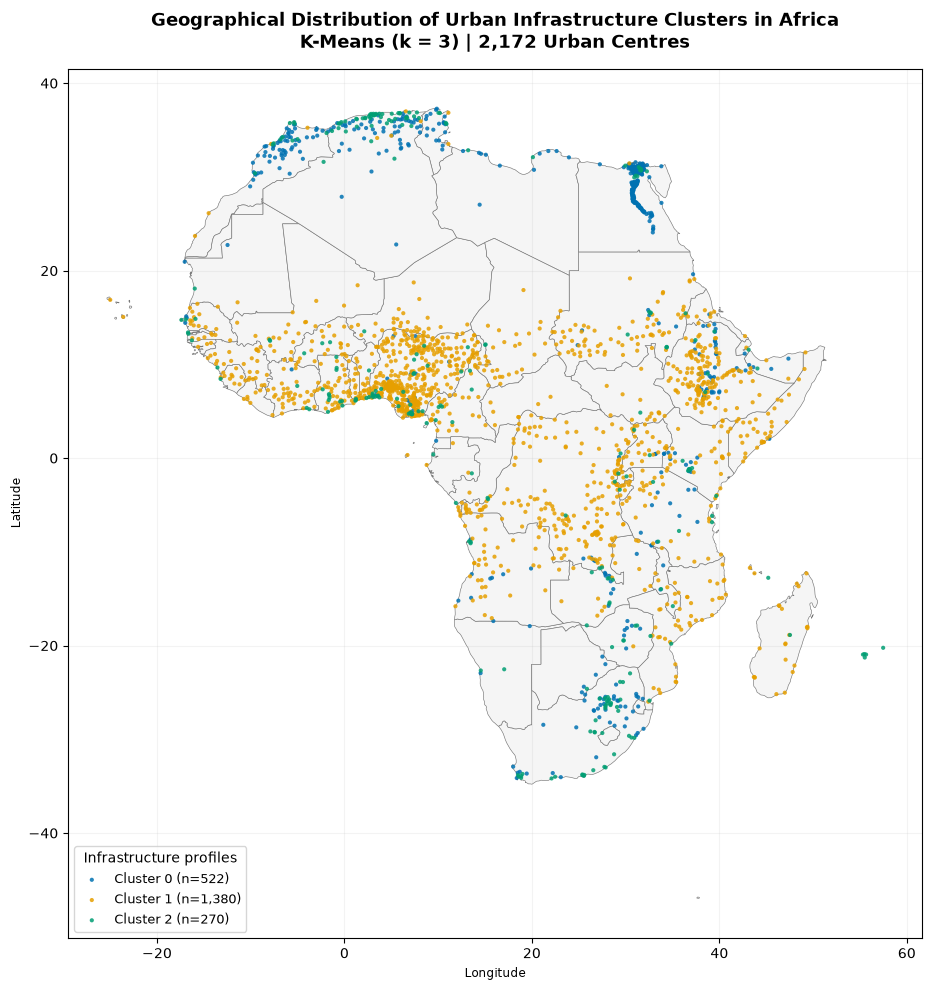

Map saved to: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\outputs\figures\africa_urban_infrastructure_clusters_k3.png


In [13]:

import matplotlib.pyplot as plt

# Categorical colours — not an AI-readiness ranking
cluster_colors = {
    0: "#0072B2",  # Blue
    1: "#E69F00",  # Orange
    2: "#009E73",  # Green
}

fig, ax = plt.subplots(figsize=(12, 10))

# Africa country boundaries
africa.plot(
    ax=ax,
    facecolor="#F5F5F5",
    edgecolor="#777777",
    linewidth=0.45,
    zorder=1
)

# Urban-centre cluster assignments
for cluster_id, color in cluster_colors.items():
    subset = gdf_map[gdf_map["KMeans_k3"] == cluster_id]

    ax.scatter(
        subset.geometry.x,
        subset.geometry.y,
        s=9,
        color=color,
        alpha=0.85,
        edgecolors="none",
        label=f"Cluster {cluster_id} (n={len(subset):,})",
        zorder=2
    )

ax.set_title(
    "Geographical Distribution of Urban Infrastructure Clusters in Africa\n"
    "K-Means (k = 3) | 2,172 Urban Centres",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="box")

ax.legend(
    title="Infrastructure profiles",
    loc="lower left",
    fontsize=9,
    frameon=True
)

ax.grid(alpha=0.15)


# Save the Africa-wide cluster map
from pathlib import Path

output_dir = Path("../outputs/figures")
output_dir.mkdir(parents=True, exist_ok=True)

map_path = output_dir / "africa_urban_infrastructure_clusters_k3.png"

plt.tight_layout()

fig.savefig(
    map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Map saved to: {map_path.resolve()}")




## Country-Level Distribution of Infrastructure Clusters

This section examines the distribution of the three K-Means infrastructure clusters across African countries.

Both absolute counts and within-country percentages are considered to distinguish the number of urban centres from their relative cluster composition.

Cluster identifiers are categorical and do not represent an ordinal ranking of AI readiness or investment suitability.


In [14]:

# Country-level distribution of K-Means (k=3) clusters

country_col = "GC_CNT_GAD_2025"
cluster_col = "KMeans_k3"

# Count urban centres by country and cluster
country_cluster_counts = pd.crosstab(
    df_geo[country_col],
    df_geo[cluster_col]
).reindex(columns=[0, 1, 2], fill_value=0)

country_cluster_counts.columns = [
    "Cluster_0",
    "Cluster_1",
    "Cluster_2"
]

# Total urban centres per country
country_cluster_counts["Total"] = (
    country_cluster_counts.sum(axis=1)
)

# Calculate within-country percentages
country_cluster_pct = (
    country_cluster_counts[
        ["Cluster_0", "Cluster_1", "Cluster_2"]
    ]
    .div(country_cluster_counts["Total"], axis=0)
    .mul(100)
    .round(1)
)

country_cluster_pct.columns = [
    "Cluster_0_pct",
    "Cluster_1_pct",
    "Cluster_2_pct"
]

# Combine counts and percentages
country_cluster_summary = (
    country_cluster_counts
    .join(country_cluster_pct)
    .sort_values("Total", ascending=False)
)

print("Countries represented:", len(country_cluster_summary))
print("Total urban centres:", country_cluster_summary["Total"].sum())

display(country_cluster_summary.head(15))


Countries represented: 56
Total urban centres: 2172


,Cluster_0,Cluster_1,Cluster_2,Total,Cluster_0_pct,Cluster_1_pct,Cluster_2_pct
GC_CNT_GAD_2025,,,,,,,
Nigeria,13,380,32,425,3.1,89.4,7.5
Egypt,200,1,13,214,93.5,0.5,6.1
Democratic Republic of the Congo,6,176,7,189,3.2,93.1,3.7
Ethiopia,38,142,4,184,20.7,77.2,2.2
Algeria,57,4,48,109,52.3,3.7,44.0
South Africa,40,0,41,81,49.4,0.0,50.6
Sudan,7,65,8,80,8.8,81.2,10.0
Morocco,59,2,11,72,81.9,2.8,15.3
Angola,9,44,3,56,16.1,78.6,5.4


### Cluster composition across selected African countries

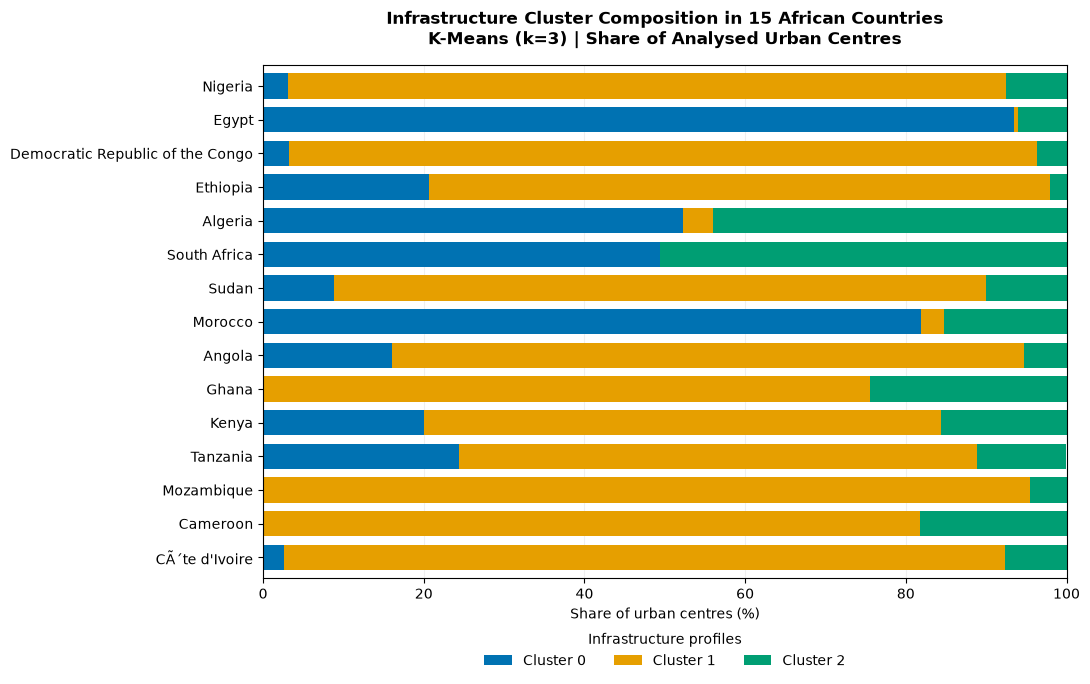

In [16]:

# Cluster composition in the 15 countries with most urban centres

import matplotlib.pyplot as plt

top15 = country_cluster_summary.head(15).copy()

# Retain the same categorical colours used in the Africa map
cluster_colors = ["#0072B2", "#E69F00", "#009E73"]

fig, ax = plt.subplots(figsize=(11, 7))

top15[
    ["Cluster_0_pct", "Cluster_1_pct", "Cluster_2_pct"]
].plot(
    kind="barh",
    stacked=True,
    color=cluster_colors,
    width=0.75,
    ax=ax
)

ax.invert_yaxis()

ax.set_title(
    "Infrastructure Cluster Composition in 15 African Countries\n"
    "K-Means (k=3) | Share of Analysed Urban Centres",
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Share of urban centres (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.legend(
    ["Cluster 0", "Cluster 1", "Cluster 2"],
    title="Infrastructure profiles",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save country-level cluster composition chart
fig.savefig(
    "../outputs/figures/africa_country_cluster_composition_k3.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Integrated Interpretation of Geographical Patterns and Infrastructure Profiles

This section integrates the geographical distribution of K-Means (k=3) clusters with their underlying infrastructure, socioeconomic and environmental characteristics.

Cluster profiles are examined using the original predictor values. Because predictors have different units and distributions, these descriptive statistics are interpreted alongside the standardized cluster profiles established in Notebook 03.

The objective is to identify distinguishing characteristics and explore their potential relevance to preliminary AI infrastructure investment screening.

Cluster identifiers are categorical and do not constitute AI-readiness rankings or validated investment suitability scores.


### Calculate cluster-level predictor summaries

In [17]:

# Cluster-level descriptive profiles using original predictor values

predictor_cols = [
    "GH_POP_TOT_2025",
    "SC_GDP_AVG_2020",
    "IN_CIS_ENE_2020",
    "IN_CIS_TEL_2020",
    "fibre_distance_band_km",
    "IN_CIS_TRA_2020",
    "IN_ROA_DEN_2024",
    "SC_SEC_SYT_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_WAT_2020",
    "CL_REN_PVO_2020",
    "CL_B01_CUR_2010"
]

# Median predictor values for each cluster
cluster_medians = (
    df_geo
    .groupby("KMeans_k3")[predictor_cols]
    .median()
    .T
)

cluster_medians.columns = [
    "Cluster 0",
    "Cluster 1",
    "Cluster 2"
]

# Number of urban centres in each cluster
cluster_sizes = (
    df_geo["KMeans_k3"]
    .value_counts()
    .sort_index()
)

print("Cluster sizes:")
print(cluster_sizes)

print("\nMedian predictor values by cluster:")
display(cluster_medians.round(3))


Cluster sizes:
KMeans_k3
0     522
1    1380
2     270
Name: count, dtype: int64

Median predictor values by cluster:


,Cluster 0,Cluster 1,Cluster 2
GH_POP_TOT_2025,1.065477e+05,8.826909e+04,2.633343e+05
SC_GDP_AVG_2020,2.946262e+07,1.183863e+07,2.789274e+07
IN_CIS_ENE_2020,2.600000e-02,0.000000e+00,2.100000e-02
IN_CIS_TEL_2020,0.000000e+00,0.000000e+00,1.000000e-03
fibre_distance_band_km,1.500000e+01,1.000000e+01,5.000000e+00
IN_CIS_TRA_2020,1.100000e-02,4.000000e-03,1.700000e-02
IN_ROA_DEN_2024,1.200000e-02,8.000000e-03,1.300000e-02
SC_SEC_SYT_2020,7.746000e+00,4.772000e+00,8.550000e+00
IN_CIS_EDU_2020,1.000000e-03,0.000000e+00,7.000000e-03
IN_CIS_WAT_2020,0.000000e+00,0.000000e+00,0.000000e+00


### Methodological Notes on Cluster-Level Predictor Summaries

**Use of median values:** Cluster-level predictor profiles are summarized using medians because several infrastructure and socioeconomic variables exhibit strongly skewed distributions. The median provides a robust measure of central tendency that is less sensitive to extreme observations than the arithmetic mean. However, medians do not capture the full variability within clusters and should be interpreted alongside the standardized cluster profiles presented in Notebook 03.

**Use of complementary summary statistics:** Cluster-level predictor profiles are examined using medians of the original indicator values and means of the transformed, standardized predictors. Raw medians provide robust descriptions of typical indicator values, particularly for skewed distributions. Standardized means are used because K-Means defines cluster centroids as arithmetic means in the feature space used for clustering. They therefore characterize the relative predictor patterns underlying the clustering solution. Although standardized medians could also be calculated, they would describe typical standardized values rather than the K-Means centroids. The two summaries serve complementary interpretive purposes and should not be treated as directly equivalent statistics.

**Fibre infrastructure proximity:** The variable `fibre_distance_band_km` represents encoded distance categories derived from proximity to terrestrial fibre infrastructure, rather than continuously measured distances. Consequently, median values such as 5, 10 or 15 should be interpreted as representative encoded distance bands, not precise distances in kilometres. The variable also does not directly measure fibre connectivity, service availability, bandwidth or affordability.

**Economic indicator:** `SC_GDP_AVG_2020` represents average GDP (PPP) as defined in the GHSL Urban Centre Database. It should not be interpreted as GDP per capita, household income or a direct measure of purchasing power at the individual level. Differences between clusters therefore describe variation in the selected economic indicator rather than individual economic prosperity.

**Infrastructure indicators and zero values:** Several GHSL infrastructure indicators have highly skewed distributions, including zero or near-zero observations. A cluster median of zero indicates that at least half of its observations have values at or below zero for that indicator. It does not necessarily establish the complete absence of the corresponding infrastructure or service. Moreover, GHSL infrastructure indicators primarily describe spatial infrastructure coverage and should not be interpreted as direct measures of service reliability, quality or operational capacity.

**Interpretation of cluster profiles:** The reported medians describe the original predictor values, whereas the K-Means clustering was performed using transformed and standardized features. Consequently, the median summaries are descriptive rather than direct representations of the distances used by the clustering algorithm. Cluster differences should be interpreted jointly with the standardized predictor profiles, geographical distributions and known limitations of the underlying data.

### Interpretation of the Three Infrastructure Clusters

The combined analysis of raw predictor medians, standardized cluster profiles and geographical distributions identifies three distinct infrastructure profiles among the 2,172 African urban centres. The interpretation is based on the selected K-Means configuration (k = 3), with cluster memberships of 522, 1,380 and 270 urban centres, respectively.

#### Cluster 0 — Relatively elevated energy infrastructure and solar potential

Cluster 0 comprises 522 urban centres (24.0% of the analytical dataset). It exhibits above-average standardized values for energy infrastructure (+1.01), average GDP (PPP) (+0.76), solar PV potential (+0.79), transport infrastructure (+0.70), road network density (+0.66) and mean years of schooling (+0.54).

Its standardized urban population (+0.02) and education infrastructure (+0.05) are close to the overall mean, while telecom infrastructure (−0.17), water infrastructure (−0.13), fibre-distance band (−0.14) and annual mean temperature (−0.73) fall below the mean.

The raw medians support this profile, particularly the relatively higher energy infrastructure index (0.026), average GDP indicator (approximately 29.46 million PPP units) and solar PV potential (4.854).

Geographically, this cluster is prominent among the analysed urban centres in parts of North Africa, particularly Egypt and Morocco, and is also represented in southern Africa.

**Interpretation:** Cluster 0 represents urban centres with relatively elevated energy infrastructure coverage and solar resource potential, accompanied by comparatively favourable values for several economic and transport-related indicators. However, its telecom and water infrastructure characteristics are less distinctive.

#### Cluster 1 — Relatively lower observed infrastructure coverage

Cluster 1 contains 1,380 urban centres (63.5%), making it the largest cluster.

Its standardized profile is below the overall mean across most infrastructure and socioeconomic predictors, including energy (−0.56), transport (−0.53), average GDP (PPP) (−0.41), road network density (−0.39), education infrastructure (−0.37), mean years of schooling (−0.35), telecom infrastructure (−0.28), solar PV potential (−0.28) and water infrastructure (−0.20).

It also has a smaller standardized urban population (−0.23), while annual mean temperature (+0.38) and fibre-distance-band values (+0.15) are above the overall mean.

The raw medians indicate comparatively lower energy and transport infrastructure indices, fewer mean years of schooling (4.77) and a higher annual mean temperature (26.13°C).

Geographically, Cluster 1 is widespread across Sub-Saharan Africa and accounts for substantial proportions of the analysed urban centres in Nigeria, the Democratic Republic of the Congo, Ethiopia and several other countries.

**Interpretation:** Cluster 1 represents urban centres characterized by comparatively lower observed infrastructure coverage and socioeconomic indicator values within the selected analytical dataset. These differences may indicate infrastructure-related constraints relevant to preliminary investment screening, but they do not independently establish deficiencies in service reliability or AI readiness.

#### Cluster 2 — Larger urban centres with relatively elevated telecom, education and transport infrastructure indicators

Cluster 2 comprises 270 urban centres (12.4%) and is distinguished by particularly elevated standardized values for education infrastructure (+1.78), telecom infrastructure (+1.75), transport infrastructure (+1.35), water infrastructure (+1.26) and urban population (+1.15).

It also exhibits above-average energy infrastructure (+0.89), mean years of schooling (+0.74), road network density (+0.70) and average GDP (PPP) (+0.64).

Its fibre-distance-band value (−0.52) is below the overall mean, consistent with relatively closer proximity to terrestrial fibre infrastructure. Solar PV potential (−0.12) and annual mean temperature (−0.53) are also below the overall mean.

The raw medians reinforce this differentiation, particularly the larger median population (approximately 263,334), higher transport infrastructure index (0.017), education infrastructure index (0.007) and mean years of schooling (8.55).

Although the median water infrastructure index is zero across all three clusters, Cluster 2 has a substantially higher standardized mean for this indicator. This illustrates why raw medians and standardized profiles must be interpreted together.

Geographically, Cluster 2 is represented in several areas, including parts of South Africa, Algeria and coastal West Africa.

**Interpretation:** Cluster 2 represents relatively larger urban centres with elevated observed indicators of telecom, education, transport and water infrastructure coverage. These characteristics may be relevant to identifying locations for more detailed AI-related infrastructure feasibility assessment, but they do not establish investment suitability or operational readiness.

#### Cross-Cluster Interpretation and Implications

The three clusters reveal multidimensional differences in infrastructure, socioeconomic and environmental conditions rather than a single progression from low to high AI readiness.

Cluster 0 is distinguished particularly by energy infrastructure and solar PV potential; Cluster 1 by comparatively lower observed values across several infrastructure and socioeconomic indicators; and Cluster 2 by larger urban populations and elevated telecom, education, transport and water infrastructure indicators.

The geographical patterns also suggest that environmental and regional characteristics contribute to cluster differentiation. In particular, differences in annual mean temperature and solar PV potential should not be interpreted as direct evidence of digital infrastructure performance.

These findings provide a preliminary framework for differentiated infrastructure investment screening. They may help identify contrasting urban infrastructure contexts, formulate location-specific investment questions and prioritize subsequent feasibility assessments.

However, the clusters are exploratory and do not constitute validated AI-readiness categories, investment rankings or evidence of project bankability. Further assessment would require additional information on electricity reliability and capacity, connectivity quality and affordability, infrastructure demand, investment costs, institutional conditions and other relevant factors.

**Cluster identifiers (0, 1 and 2) are categorical labels without inherent ordinal meaning.**

# Preliminary Investment-Screening Archetypes and Evidence Requirements



The following archetypes are exploratory interpretations of the three K-Means (k = 3) infrastructure profiles identified among 2,172 analysed African urban centres. They support differentiated follow-up screening rather than rankings of AI readiness or investment suitability.

| Cluster | Observed infrastructure profile | Preliminary screening relevance | Key constraints and evidence requirements |
|:--|:--|:--|:--|
| **Cluster 0 (n = 522)** | Relatively stronger energy infrastructure coverage and solar PV potential; higher median average GDP (PPP) indicator than Clusters 1 and 2; intermediate transport and education indicators. | Potential starting points for examining energy-linked AI infrastructure opportunities, subject to local feasibility. | Verify electricity reliability, available grid capacity, energy costs, renewable energy development potential, fibre connectivity and investment demand. |
| **Cluster 1 (n = 1,380)** | Comparatively lower observed energy, transport, education and several other infrastructure indicators; lower median average GDP (PPP) indicator and schooling; warmer climatic conditions. | Locations where screening may prioritize infrastructure-enabling requirements and development needs before assessing AI infrastructure deployment. | Assess grid access and reliability, connectivity availability, affordability, skills, infrastructure investment requirements and institutional capacity. |
| **Cluster 2 (n = 270)** | Relatively larger urban centres; stronger observed telecom, transport, education and water infrastructure indicators in the standardized cluster profiles; smaller encoded fibre proximity bands. | Potential starting points for investigating locations with several complementary infrastructure characteristics relevant to AI-related investment. | Verify actual broadband capacity, electricity reliability, water availability, land and environmental constraints, demand, costs and institutional conditions. |

### Investment-screening interpretation

The three clusters provide a preliminary basis for differentiating African urban centres according to observed infrastructure, socioeconomic and environmental characteristics. Rather than establishing a hierarchy of AI readiness, they identify contrasting infrastructure contexts that may require different investment-screening approaches.

Cluster 0 suggests opportunities to investigate energy-related enabling conditions, while Cluster 1 highlights locations where infrastructure constraints and development needs may warrant particular attention. Cluster 2 identifies urban centres with relatively stronger observed characteristics across several complementary infrastructure dimensions.

These archetypes are exploratory analytical interpretations, not independently validated investment categories. Their screening relevance is conditional on further evidence, including electricity reliability, digital connectivity performance, infrastructure capacity, costs, institutional readiness and market demand. No cluster should be interpreted as automatically more investable or more AI-ready than another.

**Decision-support boundary:** The clustering results support preliminary location differentiation and the identification of follow-up assessment priorities. They do not constitute an investment suitability score, financial feasibility assessment, project ranking or recommendation to invest.

**Indicator interpretation:** The GDP variable refers to average GDP (PPP), not GDP per capita. Fibre proximity is represented by encoded distance bands, not continuous measured distances or verified service quality. GHSL infrastructure indices primarily describe spatial infrastructure coverage, not service reliability or operational capacity. Cluster labels 0, 1 and 2 are categorical, not ordinal.

## Interpretation of Urban Infrastructure Profiles in the Context of Established AI-Enabling Factors

### Conceptual foundation

The interpretation of the three urban infrastructure clusters is informed by published evidence on the foundations of AI adoption, adaptation and innovation. The World Bank (2025) identifies four interrelated foundations—the **four Cs**: **connectivity**, **compute**, **context** (relevant data) and **competency** (skills). These foundations highlight that AI participation depends on more than the physical presence of digital infrastructure. Affordable, reliable connectivity, access to computing resources, locally relevant data and human capabilities all matter. The International Energy Agency (IEA, 2025) further demonstrates the importance of electricity supply and its energy-security, affordability and environmental implications for AI-related computing infrastructure.

The present study measures **selected proxies** relevant to these foundations, not the foundations in their entirety. Terrestrial fibre proximity bands and the GHSL telecommunications infrastructure index provide limited connectivity-related information, but neither measures broadband speed, service quality or affordability. Mean years of schooling and the education infrastructure index provide broad educational context, not AI-specific competencies. Energy infrastructure coverage and solar photovoltaic (PV) potential provide information relevant to physical infrastructure and energy-resource considerations, but not electricity reliability, available grid capacity or installed renewable generation. The analytical dataset does not directly measure computing capacity, locally relevant data ecosystems or AI governance readiness (World Bank, 2025; IEA, 2025).

### Interpretation of the three clusters

**Cluster 0 (n = 522): Relatively elevated energy infrastructure and solar-resource characteristics.** This cluster exhibits relatively stronger energy infrastructure coverage and the highest median solar PV potential among the three clusters. These characteristics are relevant to preliminary investigation of energy-related enabling conditions for AI infrastructure, particularly in view of the importance of electricity for data centres (IEA, 2025). However, solar PV potential represents a resource characteristic, **not installed solar capacity**, and the GHSL energy index does not establish grid reliability, capacity or cost. Cluster 0 therefore identifies an infrastructure context for further assessment, not an established energy-ready investment location.

**Cluster 1 (n = 1,380): Comparatively lower observed infrastructure and educational indicators.** This largest cluster shows comparatively lower values across several infrastructure and socioeconomic predictors, alongside warmer mean climatic conditions. In the context of the World Bank's four foundations, the results suggest that connectivity, foundational infrastructure and human-capability constraints merit attention in subsequent screening. Nevertheless, the indicators cannot establish whether particular cities are unable to adopt AI: access to external cloud services and different AI deployment models can reduce the need for locally hosted computing infrastructure (World Bank, 2025). The cluster should not be equated with a validated category of low AI readiness.

**Cluster 2 (n = 270): Relatively stronger complementary infrastructure characteristics.** This cluster contains comparatively larger urban centres and shows elevated standardized profiles for telecommunications, transport, education and water infrastructure indicators, together with closer encoded terrestrial-fibre proximity bands. These characteristics are relevant to examining possible complementarities among digital connectivity, general infrastructure and human-capability conditions. However, the telecom and water indicators principally describe infrastructure coverage rather than service quality or dependable operational supply. Fibre values are **encoded proximity categories**, not precise measured distances or proof of connectivity. The cluster's characteristics do not verify compute availability, AI-specific talent, investment demand or data-centre feasibility (World Bank, 2025; IEA, 2025).

### Implications for preliminary investment screening

The findings support **differentiated follow-up questions**, not a ranking of urban centres. Cluster 0 may motivate closer investigation of energy-system conditions and renewable-resource opportunities; Cluster 1 may draw attention to foundational infrastructure and capacity-building needs; and Cluster 2 may motivate investigation of the quality and operational capacity of complementary infrastructure systems. These are conditional interpretations derived from the observed profiles and the cited literature, **not empirically validated investment recommendations**.

An additional distinction is essential: **readiness to adopt or use AI is not equivalent to suitability for hosting physical AI infrastructure**. AI applications may be accessed through remote computing services, whereas local data-centre development requires site-specific evidence on electricity, connectivity, cooling, water, land, costs and regulatory conditions. Conversely, favourable physical infrastructure characteristics do not by themselves establish local AI innovation capacity or demand (World Bank, 2025; IEA, 2025).

The clusters were generated from 12 selected predictors; they are exploratory infrastructure profiles rather than independently validated AI-readiness categories. Cluster identifiers **0, 1 and 2 are nominal labels**, not ordinal scores. In addition, geographical patterns may partly reflect environmental and regional variation captured by the predictors, including temperature and solar PV potential, rather than differences in digital infrastructure performance. A subsequent investment appraisal would require additional evidence on actual electricity reliability and capacity, broadband performance and affordability, compute access, AI skills, data ecosystems, governance, demand, investment costs and environmental constraints.

### References

International Energy Agency (IEA). (2025). *Energy and AI*. IEA, Paris. https://www.iea.org/reports/energy-and-ai

World Bank. (2025). *Digital Progress and Trends Report 2025: Strengthening AI Foundations*. World Bank. https://www.worldbank.org/en/publication/dptr2025-ai-foundations/report

**Note:** The references above support the conceptual discussion; the cluster descriptions and counts come from this project's empirical analysis. The reference list can be consolidated with the report's main bibliography during final writing.